# 05 · Exploratory strategy backtest

**Objective:** Investigate whether the selected model's forecasts can
be converted into profitable trades on QQQ.

**Rule:** After the close of signal date t, predict return t→t+1.
If the predicted return is positive, buy at the **next session open**
and sell at that session's close; otherwise hold cash. No shorting or
leverage. Compare 0/5/10 basis-point round-trip costs.

**Critical limitation:** The model forecasts *close-to-close* returns,
while this implementable rule captures *open-to-close* returns. It
cannot capture overnight movement. This exploratory backtest reuses
a test period already inspected in notebook 04; it is **not** a new
independent holdout or a validated trading strategy.


## 1. Reload the exact model and saved prices

We use the same train/test split and frozen Random Forest as notebook
04, plus `data/qqq_prices.csv` from notebook 01. Using that source
snapshot avoids another vendor download with potentially revised
prices. The test data are used only to generate forecasts, not to
choose new model hyperparameters.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from src.qqq_utils import (
    FEATURE_COLUMNS, TARGET_COLUMN, chronological_split,
    load_model_data, selected_random_forest,
)

model_data = load_model_data(project_dir)
train_data, _, test_data = chronological_split(model_data)
model = selected_random_forest().fit(
    train_data[FEATURE_COLUMNS], train_data[TARGET_COLUMN]
)
test_predictions = model.predict(test_data[FEATURE_COLUMNS])

price_path = project_dir / "data" / "qqq_prices.csv"
if not price_path.exists():
    raise FileNotFoundError("Run notebook 01 first to save QQQ prices.")
price_data = pd.read_csv(price_path, index_col="Date", parse_dates=["Date"])
assert price_data.index.is_monotonic_increasing
assert not price_data.index.has_duplicates
print("Test predictions:", len(test_predictions))
print("Source price rows:", len(price_data))


Test predictions: 626
Source price rows: 4191


## 2. Align each after-close signal with the next session

Signal date and trade date are intentionally **different**. For each
prediction from date t, shift the OHLC price series to read the opening
and closing prices on t+1. We fail explicitly if a date does not match
or a future execution price is missing.


In [2]:
next_trade_dates = price_data.index.to_series().shift(-1).reindex(test_data.index)
next_open = price_data["Open"].shift(-1).reindex(test_data.index)
next_close = price_data["Close"].shift(-1).reindex(test_data.index)

backtest = pd.DataFrame({
    "Signal_Date": test_data.index,
    "Trade_Date": next_trade_dates.to_numpy(),
    "Predicted_Return_Pct": test_predictions,
    "Signal": (test_predictions > 0).astype(int),
    "Next_Open": next_open.to_numpy(),
    "Next_Close": next_close.to_numpy(),
})
if backtest[["Trade_Date", "Next_Open", "Next_Close"]].isna().any().any():
    raise ValueError("Missing next-session trading dates or OHLC prices.")

backtest = backtest.set_index("Trade_Date").sort_index()
backtest.index.name = "Trade_Date"
assert (backtest.index > backtest["Signal_Date"]).all()
assert backtest.index.is_unique

# Decimal return: +0.01 here means +1%.
backtest["Intraday_Return"] = backtest["Next_Close"] / backtest["Next_Open"] - 1
print("Trading days:", len(backtest))
print("Days long:", int(backtest["Signal"].sum()))
backtest.head()


Trading days: 626
Days long: 594


,Signal_Date,Predicted_Return_Pct,Signal,Next_Open,Next_Close,Intraday_Return
Trade_Date,,,,,,
2024-03-05,2024-03-04,0.072522,1,434.643027,429.822845,-0.011090
2024-03-06,2024-03-05,0.071767,1,434.031892,432.523743,-0.003475
2024-03-07,2024-03-06,0.071767,1,436.101895,439.088623,0.006849
2024-03-08,2024-03-07,0.072522,1,439.443407,432.750366,-0.015231
2024-03-11,2024-03-08,0.071767,1,431.262050,431.143768,-0.000274


## 3. Transaction costs and honest benchmarks

Basis points: `1 bp = 0.01% = 0.0001` in decimal returns. Costs are
charged only on days we trade. These are illustrative round-trip
assumptions, not a calibrated estimate of fees, slippage, or market
impact. Cash earns zero interest. No leverage or short positions.

**Benchmarks:** (1) buy every open and sell every close at 5 bps;
(2) conventional QQQ buy-and-hold with ~5 bps total entry/exit costs.
Buy-and-hold carries **overnight exposure**, so it is contextual rather
than a perfectly exposure-matched comparison.


In [3]:
strategy_returns = {}
for cost_bps in [0, 5, 10]:
    round_trip_cost = cost_bps / 10_000
    strategy_returns[f"Random Forest ({cost_bps} bps)"] = (
        backtest["Signal"] *
        (backtest["Intraday_Return"] - round_trip_cost)
    )

strategy_returns["Always Intraday (5 bps)"] = (
    backtest["Intraday_Return"] - 5 / 10_000
)

buy_hold_returns = price_data["Close"].pct_change().reindex(backtest.index).copy()
# Start buy-and-hold at the first open, with entry and exit costs.
buy_hold_returns.iloc[0] = backtest["Intraday_Return"].iloc[0]
buy_hold_returns.iloc[0] -= 2.5 / 10_000
buy_hold_returns.iloc[-1] -= 2.5 / 10_000
strategy_returns["Buy and Hold (5 bps)"] = buy_hold_returns

assert all(s.index.equals(backtest.index) for s in strategy_returns.values())
assert all(s.notna().all() for s in strategy_returns.values())


## 4. Compare returns and risk

Daily strategy returns are decimal fractions. Convert accumulated
growth into annualized return using 252 trading days. Annualized
volatility is daily return standard deviation times √252. Our Sharpe
ratio assumes a **zero risk-free rate**. Drawdown compares wealth to
the highest value previously reached, including initial capital.


In [4]:
def summarize_performance(daily_returns):
    equity = (1 + daily_returns).cumprod()
    annual_return = equity.iloc[-1] ** (252 / len(daily_returns)) - 1
    daily_std = daily_returns.std()
    annual_vol = daily_std * np.sqrt(252)
    sharpe = ((daily_returns.mean() / daily_std) * np.sqrt(252)
              if daily_std > 0 else np.nan)
    peak = equity.cummax().clip(lower=1.0)
    drawdown = equity / peak - 1
    return {
        "Total Return (%)": (equity.iloc[-1] - 1) * 100,
        "Annualized Return (%)": annual_return * 100,
        "Annualized Volatility (%)": annual_vol * 100,
        "Sharpe Ratio (rf=0)": sharpe,
        "Max Drawdown (%)": drawdown.min() * 100,
    }

strategy_performance = pd.DataFrame({
    name: summarize_performance(daily)
    for name, daily in strategy_returns.items()
}).T
strategy_performance.round(2)


,Total Return (%),Annualized Return (%),Annualized Volatility (%),Sharpe Ratio (rf=0),Max Drawdown (%)
Random Forest (0 bps),-9.55,-3.96,17.15,-0.15,-21.06
Random Forest (5 bps),-32.80,-14.79,17.15,-0.85,-34.62
Random Forest (10 bps),-50.08,-24.40,17.15,-1.54,-50.90
Always Intraday (5 bps),-28.89,-12.83,17.36,-0.70,-31.43
Buy and Hold (5 bps),62.56,21.60,21.28,1.03,-22.77


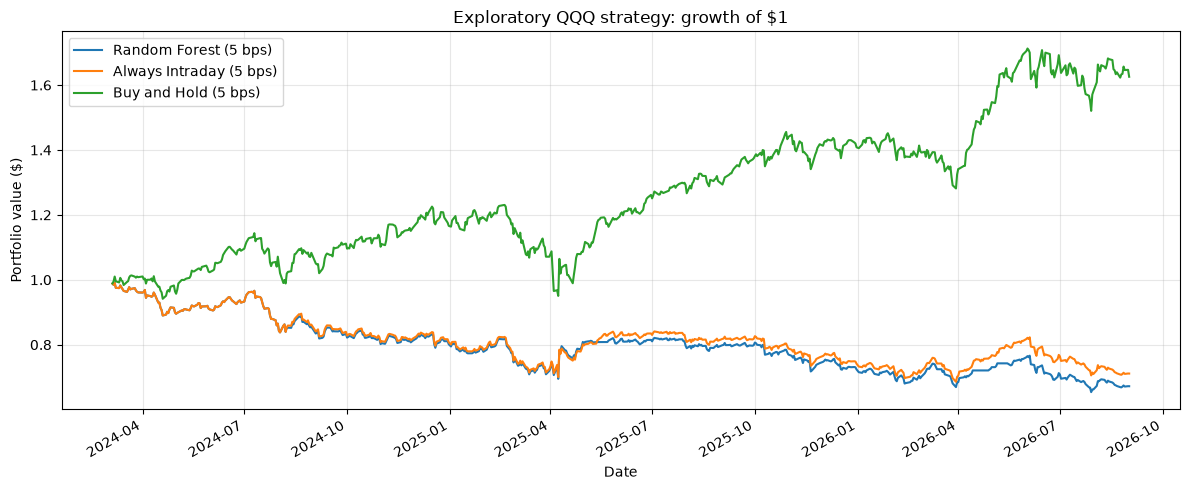

In [5]:
equity_curves = pd.DataFrame({
    name: (1 + daily).cumprod()
    for name, daily in strategy_returns.items()
})
ax = equity_curves[["Random Forest (5 bps)",
                    "Always Intraday (5 bps)",
                    "Buy and Hold (5 bps)"]].plot(figsize=(12, 5))
ax.set(title="Exploratory QQQ strategy: growth of $1",
       xlabel="Date", ylabel="Portfolio value ($)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Diagnose the binary decision rule

Positive correlation between continuous forecasts and returns need not
make the **sign-based** trading rule profitable. Check trading frequency
and average intraday returns on both invested and cash days.


In [6]:
invested = backtest["Signal"] == 1
diagnostics = pd.Series({
    "Trading sessions": len(backtest),
    "Days invested": int(invested.sum()),
    "Share of days invested (%)": invested.mean() * 100,
    "Forecast/intraday correlation": backtest["Predicted_Return_Pct"].corr(
        backtest["Intraday_Return"]),
    "Mean intraday return when invested (%)":
        backtest.loc[invested, "Intraday_Return"].mean() * 100,
    "Mean intraday return when in cash (%)":
        backtest.loc[~invested, "Intraday_Return"].mean() * 100,
})
diagnostics


Trading sessions                          626.000000
Days invested                             594.000000
Share of days invested (%)                 94.888179
Forecast/intraday correlation               0.196494
Mean intraday return when invested (%)     -0.010814
Mean intraday return when in cash (%)       0.229275
dtype: float64

## 6. Findings, limitations, and next research steps

**Recorded results from the original test-period backtest:**

- Random Forest **without** costs: approximately **−9.55%** total.
- Random Forest at **5 bps**: approximately **−32.80%** total.
- Random Forest at **10 bps**: approximately **−50.08%** total.
- Always-intraday 5 bps: approximately **−28.89%** total.
- Contextual QQQ buy-and-hold 5 bps: approximately **+62.56%** total.
- The signal was long **594 of 626 sessions (94.89%)**.

The model's continuous intraday correlation was approximately `0.1965`,
but the days when the strategy invested had slightly **negative**
average intraday returns. The rule lost money even at zero assumed
transaction costs, so costs are not the only problem.

**What we can conclude:** Small close-to-close forecasting improvements
did not produce a profitable next-open-to-close strategy in this
historical experiment. We cannot claim real-world trading alpha.

**Main limitations:** Different prediction/trading horizons; a single
ETF and historical window; illustrative execution costs; zero cash
interest and risk-free rate; no market-impact model; one fixed sign
threshold; no independently untouched *strategy* holdout.

**Future work (new research, not retroactive test tuning):** Define an
open-to-close or preclose-to-next-close target with features actually
available before execution; compare exposure-matched benchmarks;
evaluate on a new future period or rolling, strictly out-of-sample
walk-forward splits.
